In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [8]:
tips = pd.read_csv("tips.csv")
x= tips[["total_bill"]]
y = tips["tip"]
x_train, x_test, y_train, y_test = train_test_split(
    x,y, test_size=0.3, random_state=42)
print(len(x_train), len(x_test))

170 74


In [ ]:
#The model looks good on the data it learned from because it memorized it
#Holding out 30% gives the model data it has not memorized.

In [9]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train, y_train)
print(model.score(x_test, y_test))
print("slope:", model.coef_)
print("intercept:", model.intercept_)
print("test:", model.score(x_test, y_test))

0.4291782688312412
slope: [0.10889371]
intercept: 0.8769576391532699
test: 0.4291782688312412


<function matplotlib.pyplot.show(close=None, block=None)>

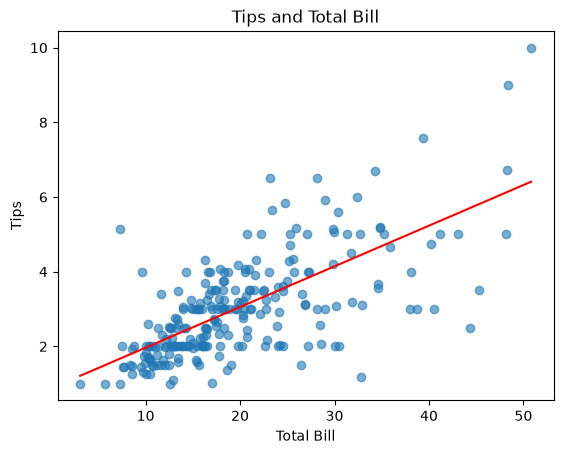

In [10]:
line_y = model.predict(x)
plt.scatter(x,y, alpha=0.6, label="Observed tips")
order =x["total_bill"].argsort()
plt.plot(x["total_bill"].iloc[order], line_y[order], color="red", label = "fitted line")
plt.xlabel("Total Bill")
plt.ylabel("Tips")
plt.title("Tips and Total Bill")
plt.show

In [13]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
x = iris.data
y = iris.target
x_train, x_test, y_train, y_test = train_test_split(
    x,y, test_size=0.3, random_state=42)
print(x_train.shape, x_test.shape)

(105, 4) (45, 4)


In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
knn = KNeighborsClassifier(n_neighbors=5)
tree = DecisionTreeClassifier(max_depth=3)
knn.fit(x_train, y_train)
print("kNN test accuracy:", knn.score(x_test, y_test))

kNN test accuracy: 1.0


Tree test accuracy: 1.0
Tree train accuracy: 0.9523809523809523


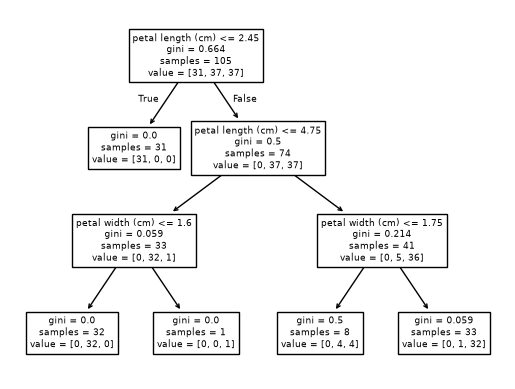

In [39]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(x_train, y_train)
print("Tree test accuracy:", tree.score(x_test, y_test))
print("Tree train accuracy:", tree.score(x_train, y_train))

plot_tree(tree, feature_names=list(x.columns))
plt.show()


No max depth tree test accuracy: 1.0
No max depth tree train accuracy: 1.0


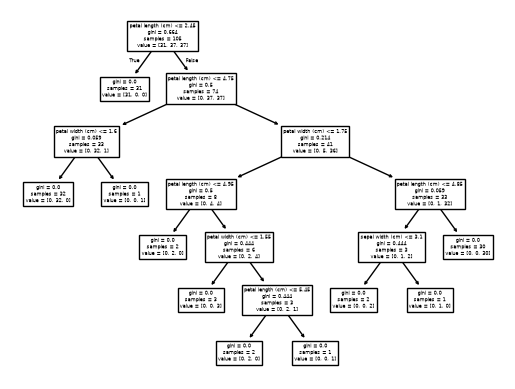

In [38]:
no_tree = DecisionTreeClassifier(random_state=42)
no_tree.fit(x_train, y_train)
print("No max depth tree test accuracy:", no_tree.score(x_test, y_test))
print("No max depth tree train accuracy:", no_tree.score(x_train, y_train))

plot_tree(no_tree, feature_names=list(x.columns))
plt.show()


In [ ]:
#The no max depth tree scores 1 on test data, but the training data is different.

In [40]:
new_flower = pd.DataFrame([[5.7, 4.0, 2.5, 3.7]], columns=x.columns)
pred = knn.predict(new_flower)[0]
print("Predicted species:", iris.target_names[pred])

Predicted species: versicolor


In [ ]:
#The model is trained to see the tips from the bill. I would ship the tree with the max_depth=3.
#It is just as accurate as the tree with no max depth. The flow chart is easy to read.
#If it where about people insterad it can risk under representing some groups. 
#The model would be unfair for them.